# DM-2 : Boosting et cartes de saillance

## 1. Exploration du jeu de données MNIST

**Objectif :** explorer le jeu de données MNIST et préparer les données pour les expériences de classification binaire avec AdaBoost.

Chaque image est représentée par 784 pixels (28 × 28) en niveaux de gris. Dans cette première partie, aucune réduction de dimension par ACP ne sera appliquée.

Les expériences porteront sur deux problèmes de classification :
- Chiffres 3 contre 8 ;
- Chiffres 0 à 4 contre chiffres 5 à 9.

Les modèles étudiés seront AdaBoost avec des arbres de décision de profondeurs 1, 3 et 8, ainsi qu'un perceptron, pour 10, 50 et 100 estimateurs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


### 1.1 Chargement des données

Le jeu de données MNIST contient 70 000 images de chiffres manuscrits, chacune représentée par 784 caractéristiques correspondant aux pixels d'une image de 28 × 28.

Les valeurs des pixels seront normalisées entre 0 et 1 afin de faciliter l'apprentissage des modèles.


In [3]:
# Chargement du jeu de données MNIST
mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False,
    parser="liac-arff"
)

# Normalisation des pixels entre 0 et 1
X = mnist.data.astype(np.float32) / 255.0

# Conversion des étiquettes en entiers
y = mnist.target.astype(int)

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("Classes disponibles :", np.unique(y))

Dimensions de X : (70000, 784)
Dimensions de y : (70000,)
Classes disponibles : [0 1 2 3 4 5 6 7 8 9]


### 1.2 Visualisation des chiffres manuscrits

Nous affichons dix exemples du jeu de données MNIST afin d'observer les différentes formes d'écriture manuscrite.

Chaque image est reconstruite à partir de son vecteur de 784 pixels.

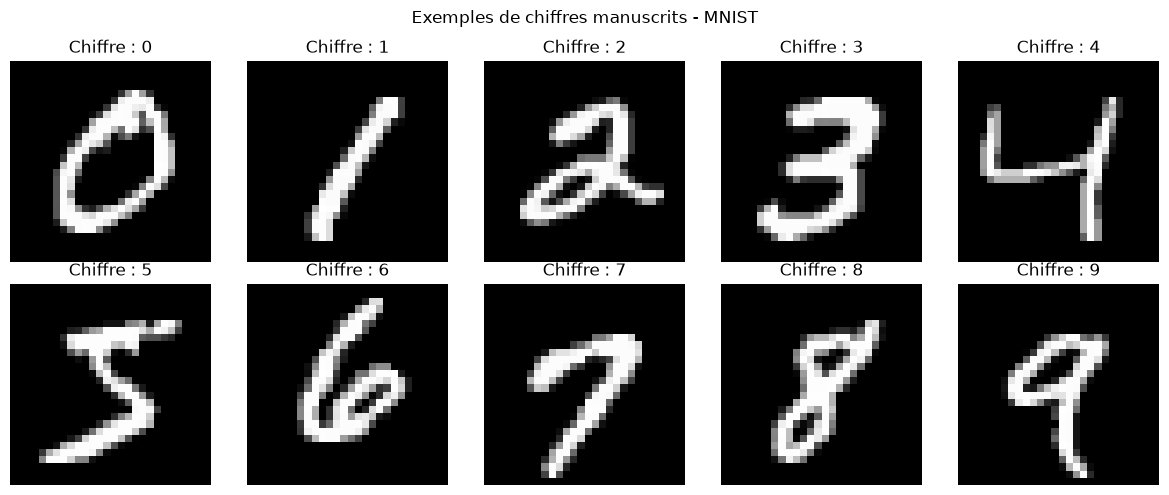

In [4]:

# Visualisation d'un exemple pour chaque chiffre de 0 à 9
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for chiffre, ax in enumerate(axes.flat):
    indice = np.where(y == chiffre)[0][0]
    image = X[indice].reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Chiffre : {chiffre}")
    ax.axis("off")

plt.suptitle("Exemples de chiffres manuscrits - MNIST")
plt.tight_layout()
plt.show()


### 1.3 Distribution des classes

Nous étudions le nombre d'observations pour chaque chiffre afin de vérifier la répartition des classes dans le jeu de données.

,Chiffre,Nombre d'images
0,0,6903
1,1,7877
2,2,6990
3,3,7141
4,4,6824
5,5,6313
6,6,6876
7,7,7293
8,8,6825
9,9,6958


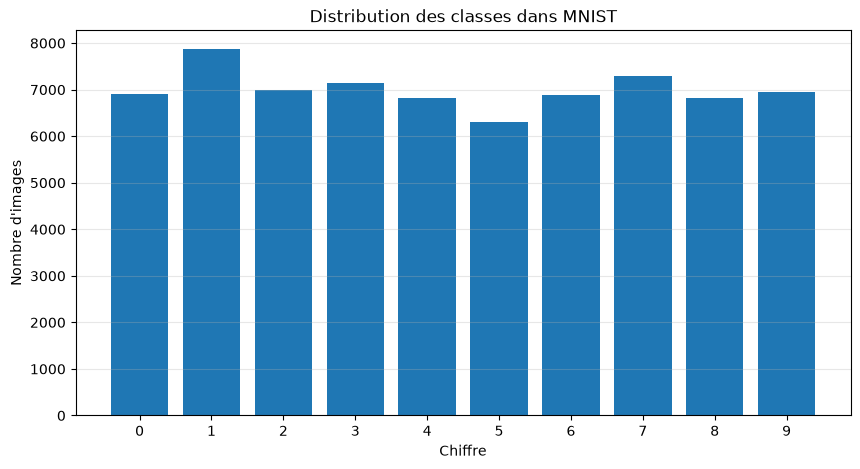

In [5]:

# Calcul de la distribution des classes
classes, counts = np.unique(y, return_counts=True)

distribution = pd.DataFrame({
    "Chiffre": classes,
    "Nombre d'images": counts
})

display(distribution)

# Représentation graphique
plt.figure(figsize=(10, 5))
plt.bar(classes, counts)

plt.xlabel("Chiffre")
plt.ylabel("Nombre d'images")
plt.title("Distribution des classes dans MNIST")
plt.xticks(classes)
plt.grid(axis="y", alpha=0.3)

plt.show()


### 1.4 Préparation des problèmes de classification binaire

Deux problèmes sont étudiés :

- **3 contre 8 :** distinguer deux chiffres manuscrits visuellement similaires.
- **0–4 contre 5–9 :** distinguer deux groupes de chiffres.

Les données sont séparées en ensembles d'entraînement (80 %) et de test (20 %), avec une stratification pour préserver les proportions des classes.

La même séparation sera conservée pour tous les modèles afin de garantir une comparaison équitable.

In [6]:

# Problème 1 : classification 3 contre 8
mask_38 = np.isin(y, [3, 8])

X_38 = X[mask_38]
y_38 = y[mask_38]

X_train_38, X_test_38, y_train_38, y_test_38 = train_test_split(
    X_38,
    y_38,
    test_size=0.2,
    random_state=42,
    stratify=y_38
)

# Problème 2 : classification 0-4 contre 5-9
# Classe 0 : chiffres de 0 à 4
# Classe 1 : chiffres de 5 à 9
y_group = (y >= 5).astype(int)

X_train_group, X_test_group, y_train_group, y_test_group = train_test_split(
    X,
    y_group,
    test_size=0.2,
    random_state=42,
    stratify=y_group
)

print("=== Problème 3 contre 8 ===")
print("Entraînement :", X_train_38.shape)
print("Test :", X_test_38.shape)

print("\n=== Problème 0-4 contre 5-9 ===")
print("Entraînement :", X_train_group.shape)
print("Test :", X_test_group.shape)


=== Problème 3 contre 8 ===
Entraînement : (11172, 784)
Test : (2794, 784)

=== Problème 0-4 contre 5-9 ===
Entraînement : (56000, 784)
Test : (14000, 784)


### 1.5 Sauvegarde des données préparées

Les ensembles d'entraînement et de test sont sauvegardés afin de pouvoir être réutilisés dans les expériences AdaBoost et dans la construction des cartes de saillance.

In [7]:

from pathlib import Path

# Répertoire principal du projet
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)

# Sauvegarde du problème 3 contre 8
np.savez_compressed(
    DATA_DIR / "mnist_3_vs_8.npz",
    X_train=X_train_38,
    X_test=X_test_38,
    y_train=y_train_38,
    y_test=y_test_38
)

# Sauvegarde du problème 0-4 contre 5-9
np.savez_compressed(
    DATA_DIR / "mnist_0_4_vs_5_9.npz",
    X_train=X_train_group,
    X_test=X_test_group,
    y_train=y_train_group,
    y_test=y_test_group
)

print("Données sauvegardées dans :", DATA_DIR)


Données sauvegardées dans : /home/lucca/00_projetos/DM2_Machine_Learning/data
